# Исследование туризма в России

## Цель и задачи проекта

**Цель** - изучить данные о туризме в России в разных регионах и выяснить, в каких из них продают больше всего услуг, какие турпакеты пользуются популярностью и как изменились предпочтения туристов за последние годы. 

**Задачи**: 
- Провести предобработку данных, убрать дубликаты и пропуски, проверить корректность числовых значений.
- Изучить распределение количества гостиниц, хостелов и санаторно-курортных организаций за 2018–2023 годы. 
- Определить регионы с наибольшей стоимостью турпакетов.
- Изучить динамику изменения количества турпакетов с 2018 по 2023 год.
- Провести статистические тесты для проверки гипотез бизнеса. 
- Подвести итоговые выводы и дать рекомендации сервису путешествий по разработке маркетинговых стретагий и предложению более персонализированных марршрутов для пользователей.

## Данные 

Данные состоят из 4 датасетов: 

`hotel.csv` - датасет содержит число гостиниц, хостелов, санаторно-курортных организаций и мест в них по субъектам Российской Федерации за 2018–2023 годы: 

- `Субъект` - наименование субъекта РФ
- `Число гостиниц`
- `Число мест в гостиницах` 
- `Число хостелов`
- `Число мест в хостелах`
- `Число санаторно-курортных организаций`
- `Число мест в санаторно-курортных организациях`. 

`count_person_hotel.csv` - датасет содержит число людей, размещённых в гостиницах по субъектам РФ в 2023 году: 

- `Субъект`
- `Численность лиц, размещенных в гостиницах в 2023 году`
- `Численность граждан России, размещенных в гостиницах в 2023 году`
- `Численность иностранных граждан, размещенных в гостиницах в 2023 году`.

`tour_firm.csv` - датасет содержит число оформленных турпакетов в 2018–2023 годы: 

- `Субъект`
- `Общее число турпакетов, реализованных населению`
- `Общее число турпакетов, реализованных гражданам России по территории России`
- `Общее число турпакетов, реализованных гражданам России по другим странам`
- `Общее число турпакетов, реализованных гражданам других стран по территории России`. 

`tour_cost_2023.csv` - датасет содержит основные показатели деятельности туристических фирм по субъектам РФ в 2023 году:
- `Субъект`
- `Стоимость реализованных турпакетов в 2023 году, млн руб.`
- `Стоимость турпакетов реализованных гражданам России по территории России в 2023 году, млн руб.`
- `Стоимость турпакетов реализованных гражданам России по другим странам в 2023 году, млн руб.`

## Структура проекта

1. Подготовка данных 
2. Исследовательский анализ данных
3. Проверка гипотез 
4. Итоговые выводы и рекомендации

### 1.Подготовка данных

#### 1.1 Изучение данных

In [1]:
#Импортируем библиотеки: 
import pandas as pd

#Импортируем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

#Импортируем библиотеку для проверки гипотез
import scipy.stats as st

#Устнавливаем вывод всех столбцов в окне
pd.set_option('display.max_columns',None)

In [2]:
#Выгружаем данные в переменные 

df_hotel = pd.read_csv('/Users/annazakharova/Downloads/hotel.csv', sep=';', low_memory=False)
df_person = pd.read_csv('/Users/annazakharova/Downloads/count_person_hotel.csv', sep=';', low_memory=False)
df_tour = pd.read_csv('/Users/annazakharova/Downloads/tour_firm.csv', sep=';', low_memory=False)
df_cost = pd.read_csv('/Users/annazakharova/Downloads/tour_cost_2023.csv', sep=';', low_memory=False)

In [3]:
#Выведем первые 5 строк каждого датафрейма и познакомимся с содержанием таблиц:
display(df_hotel.head())
display(df_person.head())
display(df_tour.head())
display(df_cost.head())

,Субъект,"Число гостиниц, 2018","Число гостиниц, 2019","Число гостиниц, 2020","Число гостиниц, 2021","Число гостиниц, 2022","Число гостиниц, 2023","Число мест в гостиницах, 2018","Число мест в гостиницах, 2019","Число мест в гостиницах, 2020","Число мест в гостиницах, 2021","Число мест в гостиницах, 2022","Число мест в гостиницах, 2023","Число хостелов, 2018","Число хостелов, 2019","Число хостелов, 2020","Число хостелов, 2021","Число хостелов, 2022","Число хостелов, 2023","Число мест в хостелах, 2018","Число мест в хостелах, 2019","Число мест в хостелах, 2020","Число мест в хостелах, 2021","Число мест в хостелах, 2022","Число мест в хостелах, 2023","Число санаторно-курортных организаций, 2018","Число санаторно-курортных организаций, 2019","Число санаторно-курортных организаций, 2020","Число санаторно-курортных организаций, 2021","Число санаторно-курортных организаций, 2022","Число санаторно-курортных организаций, 2023","Число мест в санаторно-курортных организациях, 2018","Число мест в санаторно-курортных организациях, 2019","Число мест в санаторно-курортных организациях, 2020","Число мест в санаторно-курортных организациях, 2021","Число мест в санаторно-курортных организациях, 2022","Число мест в санаторно-курортных организациях, 2023"
0,Белгородская область,97,101,103,100,101,99,4753,5144,5390,5437,5439,5486,7,11,11,11,10,8,192,288,367,366,260,200,11,11,11,11,11,11,1969,1938,1969,1969,2212,1999
1,Брянская область,74,78,86,92,91,93,3436,3507,3782,4131,4254,4414,0,0,0,0,2,3,0,0,0,0,…1,…1,15,14,14,14,14,13,2953,2829,2430,2837,2672,2937
2,Владимирская область,100,100,114,119,121,125,7679,8059,8815,8446,8913,10049,20,18,13,13,19,14,954,914,682,590,964,754,6,7,6,8,9,8,1220,1324,1205,1530,1542,1328
3,Воронежская область,141,147,151,163,170,179,9605,10419,10040,10500,10390,11468,18,10,8,7,11,9,1257,505,455,215,353,269,16,15,15,15,14,14,3241,3302,3320,3320,3243,3337
4,Ивановская область,48,52,55,74,64,59,2774,2998,3009,3796,3283,3353,7,6,6,11,9,9,184,144,139,191,255,201,14,14,14,17,15,15,4347,4341,4485,4616,4396,4293


,Субъект,"Численность лиц, размещенных в гостиницах в 2023 году","Численность граждан России, размещенных в гостиницах в 2023 году","Численность иностранных граждан, размещенных в гостиницах в 2023 году"
0,Белгородская область,180442,177536,2906
1,Брянская область,182217,173980,8237
2,Владимирская область,526768,517456,9312
3,Воронежская область,760489,732562,27927
4,Ивановская область,227632,225030,2602


,Субъект,"Общее число турпакетов, реализованных населению, 2018","Общее число турпакетов, реализованных гражданам России по территории России, 2018","Общее число турпакетов, реализованных гражданам России по другим странам, 2018","Общее число турпакетов, реализованных гражданам других стран по территории России, 2018","Общее число турпакетов, реализованных населению, 2019","Общее число турпакетов, реализованных гражданам России по территории России, 2019","Общее число турпакетов, реализованных гражданам России по другим странам, 2019","Общее число турпакетов, реализованных гражданам других стран по территории России, 2019","Общее число турпакетов, реализованных населению, 2020","Общее число турпакетов, реализованных гражданам России по территории России, 2020","Общее число турпакетов, реализованных гражданам России по другим странам, 2020","Общее число турпакетов, реализованных гражданам других стран по территории России, 2020","Общее число турпакетов, реализованных населению, 2021","Общее число турпакетов, реализованных гражданам России по территории России, 2021","Общее число турпакетов, реализованных гражданам России по другим странам, 2021","Общее число турпакетов, реализованных гражданам других стран по территории России, 2021","Общее число турпакетов, реализованных населению, 2022","Общее число турпакетов, реализованных гражданам России по территории России, 2022","Общее число турпакетов, реализованных гражданам России по другим странам, 2022","Общее число турпакетов, реализованных гражданам других стран по территории России, 2022","Общее число турпакетов, реализованных населению, 2023","Общее число турпакетов, реализованных гражданам России по территории России, 2023","Общее число турпакетов, реализованных гражданам России по другим странам, 2023","Общее число турпакетов, реализованных гражданам других стран по территории России, 2023"
0,Белгородская область,14138,4333,9805,NaN,20646,4772,15874,NaN,9694,5462,4232,NaN,14901,5662,9239.0,NaN,15222,8887,6165,170.0,17733,11803,5930.0,NaN
1,Брянская область,9444,4438,5004,2.0,10459,4966,5492,1,3435,2336,1099,NaN,7301,3822,3479.0,NaN,11591,8265,3326,NaN,10165,5377,4788.0,NaN
2,Владимирская область,23900,12294,11243,363.0,23065,11558,10394,1113,7334,4282,2978,74.0,14730,8297,6426.0,7,18288,11359,6924,5.0,22334,13588,8737.0,9.0
3,Воронежская область,14554,8124,6430,NaN,14464,4613,9851,NaN,6681,3500,3181,NaN,16296,8373,7923.0,NaN,20958,13608,7350,NaN,24993,14781,10212.0,NaN
4,Ивановская область,17049,6592,10457,NaN,17019,8327,8692,NaN,6477,4167,2310,NaN,10167,5722,4445.0,NaN,13637,8575,5062,NaN,18904,11002,7902.0,NaN


,Субъект,"Стоимость реализованных турпакетов в 2023 году, млн руб.","Стоимость турпакетов реализованных гражданам России по территории России в 2023 году, млн руб.","Стоимость турпакетов реализованных гражданам России по другим странам в 2023 году, млн руб."
0,Белгородская область,1731.9856000000002,451.745,1280.2406
1,Брянская область,1409.2361,455.8798,953.3563
2,Владимирская область,2619.7022,912.2325,1706.2733999999998
3,Воронежская область,2877.2381,688.3641,2188.874
4,Ивановская область,1906.7206999999999,612.5177,1294.203


#### 1.2 Редактирование названий полей

Мы видим, что названия столбцов достаточно громоздкие и нечитаемые, поэтому сократим их и приведём к формату `snake_case` для дальнейшей работы с данными. 

In [4]:
#Импортиурем регулярные выражения
import re

#Создаём словарь для перевода названий
metric_map = {
     'гостиниц':'hotels',
     'гостиницах':'rooms_in_hotels',
     'хостелов':'hostels',
     'хостелах':'rooms_in_hostels',
     'организаций':'sanres',
     'организациях':'rooms_in_sanres'
 }
    
pattern = re.compile(r'(?P<metric>\b(гостиниц|гостиницах|хостелов|хостелах|организаций|организациях)\b).*?(?P<year>201[8-9]|202[0-3])')

def rename_column(col_name):
    match = pattern.search(col_name)
    if not match:
        return col_name
    raw_metric = match.group('metric')
    year = match.group('year')
    short_metric = metric_map.get(raw_metric, raw_metric)
    return f"{short_metric}_{year}"

df_hotel.columns = [rename_column(c) for c in df_hotel.columns]

In [5]:
#Изменим название первого столца в датасете df_hotel
df_hotel = df_hotel.rename(columns={'Субъект':'region'})

In [6]:
#Переименуем столбцы датасета df_person
df_person = df_person.rename(columns = {
    'Субъект':'region',
    'Численность лиц, размещенных в гостиницах в 2023 году':'all_guests_2023)',
    'Численность граждан России, размещенных в гостиницах в 2023 году':'russian_guests_2023',
    'Численность иностранных граждан, размещенных в гостиницах в 2023 году':'foreign_guests_2023'
})

In [7]:
#Переименуем столбцы датасета df_tour
#Создаём словарь для перевода названий: 
metric_map_2 = {
    'населению':'all_tours',
    'гражданам России по территории России':'russia_tours_by_russian',
    'гражданам России по другим странам':'foreign_tours_by_russian',
    'гражданам других стран по территории России':'russia_tours_by_foreigns'
}

pattern_2 = re.compile(r'(?P<metric>\b(населению|гражданам России по территории России|гражданам России по другим странам|гражданам других стран по территории России)\b).*?(?P<year>201[8-9]|202[0-3])')

def rename_column_2(col_name):
    match = pattern_2.search(col_name)
    if not match:
        return col_name
    raw_metric = match.group('metric')
    year = match.group('year')
    short_metric = metric_map_2.get(raw_metric, raw_metric)
    return f"{short_metric}_{year}"

df_tour.columns = [rename_column_2(c) for c in df_tour.columns]
df_tour = df_tour.rename(columns = {'Субъект':'region'})

In [8]:
#Переименуем столбцы датасета df_cost 
cols_to_rename = {
    0:'region',
    1:'cost_tours_2023',
    2:'cost_tours_in_russia_2023',
    3:'cost_tours_in_foreign_countries_2023'
}
new_columns = list(df_cost.columns)
for idx, new_name in cols_to_rename.items():
    new_columns[idx] = new_name
    
df_cost.columns = new_columns

Столбцы во всех датасетах переименованы, теперь подробнее посмотрим на данные, которые в них содержатся: 

In [9]:
df_hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   region                 81 non-null     object
 1   hotels_2018            81 non-null     int64 
 2   hotels_2019            81 non-null     int64 
 3   hotels_2020            81 non-null     int64 
 4   hotels_2021            81 non-null     int64 
 5   hotels_2022            81 non-null     int64 
 6   hotels_2023            81 non-null     int64 
 7   rooms_in_hotels_2018   81 non-null     int64 
 8   rooms_in_hotels_2019   81 non-null     int64 
 9   rooms_in_hotels_2020   81 non-null     int64 
 10  rooms_in_hotels_2021   81 non-null     int64 
 11  rooms_in_hotels_2022   81 non-null     int64 
 12  rooms_in_hotels_2023   81 non-null     int64 
 13  hostels_2018           81 non-null     int64 
 14  hostels_2019           81 non-null     int64 
 15  hostels_2020           81

Мы видим, что данные полные, пропусков нет, однако тип данных `object` не соответсвует содержимому в столбцах с количеством номеров в хостелах и санаториях, где должны содержатся целые числа. Поэтому исследуем, почему там получился такой тип данных и преобразуем его в `int`. 

In [10]:
df_person.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   region               82 non-null     object
 1   all_guests_2023)     82 non-null     int64 
 2   russian_guests_2023  82 non-null     int64 
 3   foreign_guests_2023  82 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 2.7+ KB


В этом датасете данные полные и их формат соответсвует тому, что продставлено в названиях столбцов. 

In [11]:
df_tour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   region                         82 non-null     object 
 1   all_tours_2018                 82 non-null     object 
 2   russia_tours_by_russian_2018   82 non-null     object 
 3   foreign_tours_by_russian_2018  81 non-null     object 
 4   russia_tours_by_foreigns_2018  62 non-null     float64
 5   all_tours_2019                 82 non-null     object 
 6   russia_tours_by_russian_2019   82 non-null     object 
 7   foreign_tours_by_russian_2019  82 non-null     object 
 8   russia_tours_by_foreigns_2019  63 non-null     object 
 9   all_tours_2020                 82 non-null     object 
 10  russia_tours_by_russian_2020   82 non-null     object 
 11  foreign_tours_by_russian_2020  82 non-null     object 
 12  russia_tours_by_foreigns_2020  43 non-null     float

тип данных также отображен неверно в большинстве случаев: количество туров необходимо выразить в целочисленных значениях формата данных `int`.  

In [12]:
df_cost.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype 
---  ------                                --------------  ----- 
 0   region                                87 non-null     object
 1   cost_tours_2023                       87 non-null     object
 2   cost_tours_in_russia_2023             87 non-null     object
 3   cost_tours_in_foreign_countries_2023  87 non-null     object
dtypes: object(4)
memory usage: 2.8+ KB


В этом датасете пропуски отсутвуют, однако необходимо для дальнейшего анализа изменить формат данных на `float`. 

Таким образом, в датасетах `df_hotel` мы изменяем тип данных на `int`, в тех столбцах где содержатся целые числа. 

В датасете `df_cost` меняем тип данных в 3 столбцах на `float`. 

В датасете `df_tour` изучаем пропуски и меняем тип данных на целочсиленный. 

#### 1.3 Изменение типов данных

На примере одного из столбцов проверим, почему мы получили в числовых данных тип `object`.

In [13]:
#Выведем уникальные значения в столбце rooms_in_hostels_2018
df_hotel['rooms_in_hostels_2018'].unique()

array(['192', '0', '954', '1257', '184', '432', '356', '…1', '350',
       '5822', '352', '226', '491', '341', '428', '94749', '284', '163',
       '195', '1398', '1059', '675', '814', '439', '221', '8833', '1144',
       '6291', '136', '1494', '1183', '151', '375', '648', '667', '741',
       '3815', '329', '206', '854', '173', '2731', '589', '1178', '1661',
       '150', '199', '2671', '1399', '483', '571', '1081', '597', '787',
       '806', '307', '466', '83', '134', '261', '662', '924', '106',
       '256'], dtype=object)

Видим, что содержится значение 'nan', которое не даёт привести столбец к целочисленному формату, поэтому создадим цикл, в котором сначала приведём данные к типу `float`, а затем их приведём к необходмимоу формату с помощью метода `astype(Int64)`.

In [14]:
#Изменяем тип данных в датасете df_hotel
new_data_types = [
    'rooms_in_hostels_2018',
    'rooms_in_hostels_2019',
    'rooms_in_hostels_2020',
    'rooms_in_hostels_2021',
    'rooms_in_hostels_2022',
    'rooms_in_hostels_2023',
    'rooms_in_sanres_2018',
    'rooms_in_sanres_2019',
    'rooms_in_sanres_2020',
    'rooms_in_sanres_2021',
    'rooms_in_sanres_2022',
    'rooms_in_sanres_2023'
]

for col in new_data_types:
    df_hotel[col] = pd.to_numeric(df_hotel[col],errors = 'coerce').astype('Int64')

In [15]:
df_hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   region                 81 non-null     object
 1   hotels_2018            81 non-null     int64 
 2   hotels_2019            81 non-null     int64 
 3   hotels_2020            81 non-null     int64 
 4   hotels_2021            81 non-null     int64 
 5   hotels_2022            81 non-null     int64 
 6   hotels_2023            81 non-null     int64 
 7   rooms_in_hotels_2018   81 non-null     int64 
 8   rooms_in_hotels_2019   81 non-null     int64 
 9   rooms_in_hotels_2020   81 non-null     int64 
 10  rooms_in_hotels_2021   81 non-null     int64 
 11  rooms_in_hotels_2022   81 non-null     int64 
 12  rooms_in_hotels_2023   81 non-null     int64 
 13  hostels_2018           81 non-null     int64 
 14  hostels_2019           81 non-null     int64 
 15  hostels_2020           81

In [16]:
#Меняем тип данных в датасете df_cost
new_type_columns = ['cost_tours_2023', 'cost_tours_in_russia_2023', 'cost_tours_in_foreign_countries_2023']

for col in new_type_columns:
    df_cost[col] = pd.to_numeric(df_cost[col], errors = 'coerce')

In [17]:
df_cost.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   region                                87 non-null     object 
 1   cost_tours_2023                       85 non-null     float64
 2   cost_tours_in_russia_2023             85 non-null     float64
 3   cost_tours_in_foreign_countries_2023  85 non-null     float64
dtypes: float64(3), object(1)
memory usage: 2.8+ KB


In [18]:
#Преобразуем тип данных в датасете df_tour с помощью цикла

for col in df_tour.columns:
    converted = pd.to_numeric(df_tour[col],errors = 'coerce')
    if converted.count() / len(converted) > 0.5:
        df_tour[col] = converted.astype('Int64')
    else:
        pass

In [19]:
df_tour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   region                         82 non-null     object
 1   all_tours_2018                 78 non-null     Int64 
 2   russia_tours_by_russian_2018   78 non-null     Int64 
 3   foreign_tours_by_russian_2018  79 non-null     Int64 
 4   russia_tours_by_foreigns_2018  62 non-null     Int64 
 5   all_tours_2019                 78 non-null     Int64 
 6   russia_tours_by_russian_2019   78 non-null     Int64 
 7   foreign_tours_by_russian_2019  78 non-null     Int64 
 8   russia_tours_by_foreigns_2019  59 non-null     Int64 
 9   all_tours_2020                 78 non-null     Int64 
 10  russia_tours_by_russian_2020   78 non-null     Int64 
 11  foreign_tours_by_russian_2020  78 non-null     Int64 
 12  russia_tours_by_foreigns_2020  43 non-null     Int64 
 13  all_tou

#### 1.4 Работа с пропусками 

После изучения и преобразования данных мы видим,что полным является только датасет `df_person`. 
Поэтому рассмотрим пропуски в остальных датасетах подробнее. 

In [20]:
#Создадим функцию для выделения пропусков в данных в формате количества и доли

def show_missing_stats(tmp0):

    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]    
    
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm'))

In [21]:
#Выведем пропуски в датасете df_hotel
show_missing_stats(df_hotel)

,Кол-во пропусков,Доля пропусков
rooms_in_hostels_2018,13,0.1605
rooms_in_hostels_2019,13,0.1605
rooms_in_hostels_2020,19,0.2346
rooms_in_hostels_2021,12,0.1481
rooms_in_hostels_2022,8,0.0988
rooms_in_hostels_2023,9,0.1111
rooms_in_sanres_2018,11,0.1358
rooms_in_sanres_2019,11,0.1358
rooms_in_sanres_2020,10,0.1235
rooms_in_sanres_2021,12,0.1481


Видим, что основная часть пропусков содержится в количестве номеров в хостелах и санаториях. Оставим пропуски как есть, чтобы не создавать синтетические данные и не удалять важные для анализа строки.  

In [22]:
#Выведем пропуски в датасете df_cost
show_missing_stats(df_cost)

,Кол-во пропусков,Доля пропусков
cost_tours_2023,2,0.0230
cost_tours_in_russia_2023,2,0.0230
cost_tours_in_foreign_countries_2023,2,0.0230


Здесь причина пропуска скорее всего кроется в том, что данные о стоимости туров не были подгружены в одних и тех же субъектах РФ. Так как процент пропусков небольшой, поэтому данные можно удалить.

In [23]:
#Удалим пропуски в датасете
new_df_cost = df_cost.dropna()

In [24]:
#Выведем пропуски в датасете df_tour 
show_missing_stats(df_tour)

,Кол-во пропусков,Доля пропусков
all_tours_2018,4,0.0488
russia_tours_by_russian_2018,4,0.0488
foreign_tours_by_russian_2018,3,0.0366
russia_tours_by_foreigns_2018,20,0.2439
all_tours_2019,4,0.0488
russia_tours_by_russian_2019,4,0.0488
foreign_tours_by_russian_2019,4,0.0488
russia_tours_by_foreigns_2019,23,0.2805
all_tours_2020,4,0.0488
russia_tours_by_russian_2020,4,0.0488


Наибольшее количество пропусков встречается в тех столбцах, где отображены туры иностранных граждан по территории РФ. Предположительная причина появления этих пропусков - покупка туров иностранцами вне РФ. 
Так как доля пропусков составляет около 50% от всех данных, то мы не будем их менять и удалять, так как изменения могут очень сильно повлиять на выводы. 

Таким образом, мы обработали данные: изменили названия, тип данных, удалили пропуски в датасете `df_cost`. Пропуски в остальных датасетах оставили как есть, чтобы они не повлияли на качество данных. 
____

### 2. Исследовательский анализ данных

#### 2.1. Распределение количества гостиниц, хостелов и санаторно-курортных организаций за 2018–2023 годы.

Рассмотрим, как распределяется количество разных видов организаций в разные годы.

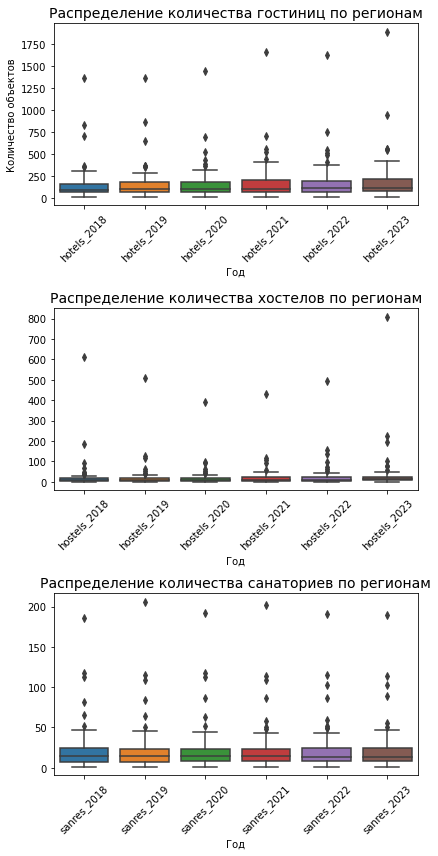

In [51]:
# Построим графики распределений количества гостиниц, хостелов и санаториев
fig, axes = plt.subplots(3, 1, figsize=(6, 12))

# Распределение гостиниц

hotel_cols = df_hotel.filter(regex=r'^hotels_\d{4}$').columns

sns.boxplot(data=df_hotel[hotel_cols], ax=axes[0])
axes[0].set_title('Распределение количества гостиниц по регионам', fontsize=14)
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Количество объектов')
axes[0].tick_params(axis='x', rotation=45) 

# Распределение хостелов
hostel_cols = df_hotel.filter(regex=r'^hostels_\d{4}$').columns
sns.boxplot(data=df_hotel[hostel_cols], ax=axes[1])
axes[1].set_title('Распределение количества хостелов по регионам', fontsize=14)
axes[1].set_xlabel('Год')
axes[1].set_ylabel('') 
axes[1].tick_params(axis='x', rotation=45)

# Распределение санаториев
sanres_cols = df_hotel.filter(regex=r'^sanres_\d{4}$').columns 
sns.boxplot(data=df_hotel[sanres_cols], ax=axes[2])
axes[2].set_title('Распределение количества санаториев по регионам', fontsize=14)
axes[2].set_xlabel('Год')
axes[2].set_ylabel('')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Мы видим, что медиана количества гостиниц и хостелов растёт незначительно. Однако, по этим видам размещения туристов есть выбросы, которые увеличиваются к 2023 году. Это говорит о том, что есть отдельные регионы, в которых число отелей и хостелов значительно увеличилось. Особенно яркий рост виден числа хостелов в 2023 году по сравнению с 2022.  

Медиана количества гостиниц, наоборот, медленно снижается. Однако, есть отдельные регионы, в которых количество санаториев очень большое, по сравнению с медианой по всем регионам. Они также формируют выбросы. Но стоить заметить, что в санаториях выбросы тоже постепенно снижаются, то есть тренд на снижение количества санаториев есть во всех регионах.  

По всем регионам мы видим, что отели являются наиболее распространенным видом размещения туристов. Медиана этого распределения находится выше примерно в 10 раз, чем у хостелов и санаториев. 

#### 2.2 регионы России с наибольшей стоимостью турпакетов в 2023 году

In [52]:
# Найдём регионы с наибольшей стоимостью турпакетов в 2023 году
cost_sorted = new_df_cost.sort_values(by='cost_tours_2023', ascending = False)
high_cost_region = cost_sorted[['region','cost_tours_2023']].set_index('region').head(10)
high_cost_region

,cost_tours_2023
region,
г. Москва,388215.5477
Московская область,27151.9902
г. Санкт-Петербург,23785.7731
Тюменская область,14332.6665
Свердловская область,14271.0682
Краснодарский край,14250.5485
Республика Татарстан,13768.8762
Пермский край,12592.6389
Нижегородская область,11545.6481


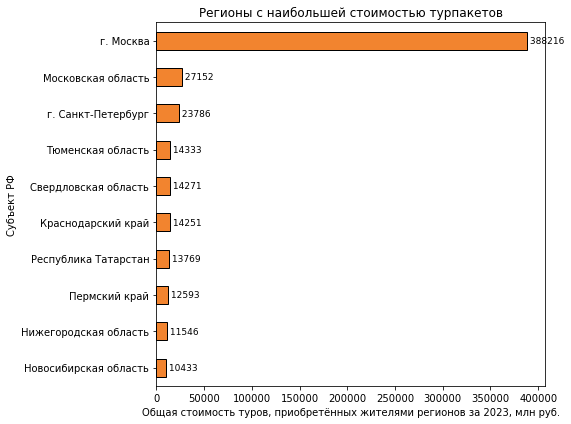

In [54]:
# Построим диаграмму
ax = high_cost_region.sort_values(by ='cost_tours_2023').plot(
    kind = 'barh',
    title=f'Регионы с наибольшей стоимостью турпакетов',
    legend=False,
    color = '#F2842F',
    edgecolor = 'k',
    figsize=(8,6)
)
plt.xlabel('Общая стоимость туров, приобретённых жителями регионов за 2023, млн руб.')
plt.ylabel('Субъект РФ')

for patch in ax.patches:
    width = patch.get_width()
    y = patch.get_y() + patch.get_height() / 2
    label_text = f'{width: .0f}'
    ax.text(width + 0.5, y, label_text, ha='left', va='center', fontsize=9, color='black')
    
plt.tight_layout()
plt.show()

Таким образом, мы видим, что Москва очень сильно выделяется из всех регионов, её жители приобрели туры на сумму в 14 раз и более, чем в любом другом регионе РФ. Поэтому жителей Москвы можно считать основной целевой аудиторией для продажи туров.

Однако, необходимо рассмотреть, какие регионы также являются развивающимися и потенциально интересными для продажи туров. 
Поэтому посмотрим на динамику количества туров 2022-2023 годов в разных регионах, чтобы выявить растущие рынки. 

#### 2.3 Топ 5 регионов России по приросту количества туров в 2023 году

In [32]:
#Создадим столбцы с абсолютным и относительным приростом в 2023 году

df_tour['growth_abs'] = df_tour['russia_tours_by_russian_2023'] - df_tour['russia_tours_by_russian_2022']
df_tour['growth_rel'] = (df_tour['russia_tours_by_russian_2023'] - df_tour['russia_tours_by_russian_2022'])/df_tour['russia_tours_by_russian_2022']*100

In [70]:
#Выведем топ 5 регионов с самым высоким абсолютным приростом
top5_region = df_tour[['region','growth_abs']].sort_values(by='growth_abs', ascending=False).set_index('region').head()
top5_region

,growth_abs
region,
г.Москва,215940
Республика Татарстан,50962
Ростовская область,26019
Пермский край,22295
Республика Дагестан,17912


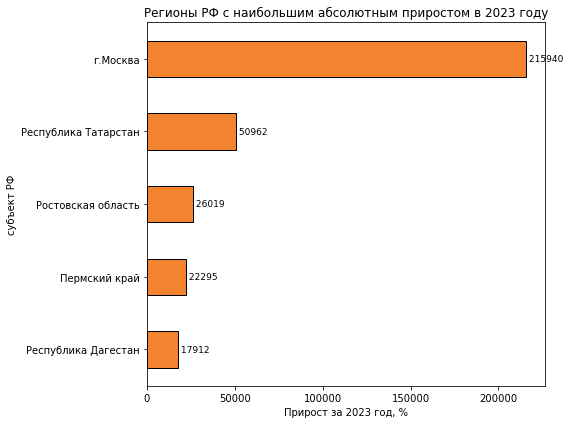

In [71]:
ax = top5_region.sort_values(by ='growth_abs').plot(
    kind = 'barh',
    title=f'Регионы РФ с наибольшим абсолютным приростом в 2023 году',
    legend=False,
    color = '#F2842F',
    edgecolor = 'k',
    figsize=(8,6)
)
plt.xlabel('Прирост за 2023 год, %')
plt.ylabel('субъект РФ')

for patch in ax.patches:
    width = patch.get_width()
    y = patch.get_y() + patch.get_height() / 2
    label_text = f'{width: .0f}'
    ax.text(width + 0.5, y, label_text, ha='left', va='center', fontsize=9, color='black')
    
plt.tight_layout()
plt.show()

Кроме Москвы республики Татарстан и Дагестан показывают наибольший абсолютный прирост количества купленных туров в 2023 году, а также Ростовская область и Пермский край. Эти регионы являются приоритетными для развития туризма. 

Рассмотрим, какие регионы также могут в дальнейшем показывать неплохой прирост и в какие направления, возможно, стоит вложиться в дальнейшем. 

In [67]:
# Выведем топ 5 регионов с самым высоким относительным приростом 
top5_rel_growth_region = df_tour[['region','growth_rel']].sort_values(by='growth_rel', ascending=False).set_index('region').head()
top5_rel_growth_region

,growth_rel
region,
Республика Дагестан,114.908904
Смоленская область,92.620321
Республика Татарстан,89.946698
Сахалинская область,74.426989
Республика Адыгея,55.273632


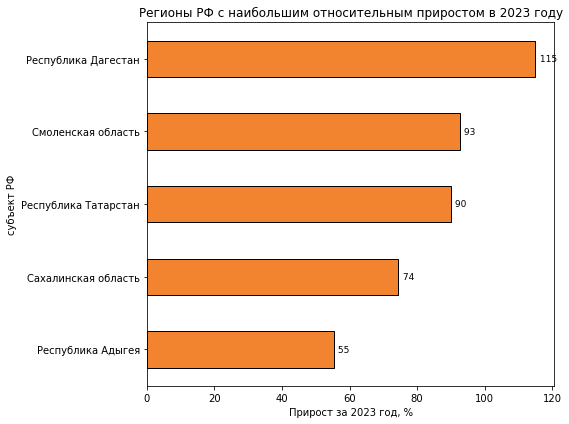

In [36]:
ax = top5_rel_growth_region.sort_values(by ='growth_rel').plot(
    kind = 'barh',
    title=f'Регионы РФ с наибольшим относительным приростом в 2023 году',
    legend=False,
    color = '#F2842F',
    edgecolor = 'k',
    figsize=(8,6)
)
plt.xlabel('Прирост за 2023 год, %')
plt.ylabel('субъект РФ')

for patch in ax.patches:
    width = patch.get_width()
    y = patch.get_y() + patch.get_height() / 2
    label_text = f'{width: .0f}'
    ax.text(width + 0.5, y, label_text, ha='left', va='center', fontsize=9, color='black')
    
plt.tight_layout()
plt.show()

Таким образом, мы видим, что что наиболее перспективными для дальнейшего развития туризма являются регионы: `Республики Татарстан и Дагестан`. Они находятся в первой пятёрке по относительному и абсолютному приросту. 
`Смоленская область`, `Сахалинская область`,`Республика Адыгея` могут быть интересны для дальнейшего развития. Здесь ниша ещё может быть свободна, а интерес к путешествиям у людей прослеживается. 

#### 2.4 Изменение среднего количества туров в России 2018 - 2023

In [28]:
# Найдём среднее количество туров в России в период 2018-2023
df_means = df_tour.mean(numeric_only = True)

In [29]:
# Создадим датафрейм с категорией тура и его средним количеством
df_long = pd.DataFrame({
    'metric': df_means.index,
    'avg_value': df_means.values
})

In [55]:
# Распределеим категорию на тип тура и год, в который он был осуществлён
df_long[['category', 'year']] = df_long['metric'].str.extract(r'(.*)_(\d{4})$')
df_long

,metric,avg_value,category,year
0,all_tours_2018,58742.025641,all_tours,2018
1,russia_tours_by_russian_2018,20957.307692,russia_tours_by_russian,2018
2,foreign_tours_by_russian_2018,32586.139241,foreign_tours_by_russian,2018
3,russia_tours_by_foreigns_2018,6046.661290,russia_tours_by_foreigns,2018
4,all_tours_2019,68328.756410,all_tours,2019
5,russia_tours_by_russian_2019,27014.910256,russia_tours_by_russian,2019
6,foreign_tours_by_russian_2019,37287.910256,foreign_tours_by_russian,2019
7,russia_tours_by_foreigns_2019,5322.423729,russia_tours_by_foreigns,2019
8,all_tours_2020,40049.038462,all_tours,2020
9,russia_tours_by_russian_2020,26833.589744,russia_tours_by_russian,2020


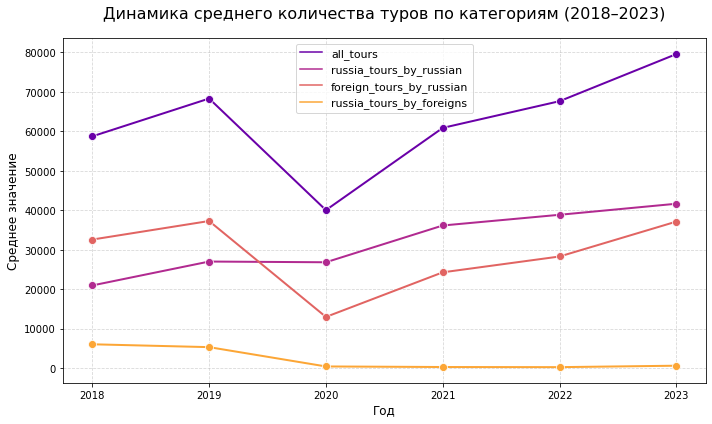

In [56]:
# Построим динамику среднего количества туров по категориям
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_long, 
    x='year', 
    y='avg_value', 
    hue='category', 
    marker='o', 
    linewidth=2, 
    markersize=8,
    palette='plasma'
)

plt.title('Динамика среднего количества туров по категориям (2018–2023)', fontsize=16, pad=20)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Среднее значение', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title=None, fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

1. На графике мы видим резкое снижение количества туров в 2020 году по 2 категориям: путешествия заграницу и путешествия по России иностранцами. Это связано с фактором пандемии. 

2. Происходит развитие туризма внутри страны. С каждым годом количество туров увеличивается, пик находится в 2023 году. Это направление является приоритетным. 

3. К 2023 году происходит увеличение количества туров заграницу и практически доходит до значения 2019 года. 

Таким образом, по линиям тренда видно, что основную популярность сейчас имеют туры по России и международные туры. 

### 3.Проверка гипотез

#### 3.1 Стоимость турпакетов в 2023 году

Сформулируем нулевую и альтернативную гипотезы: 

- Нулевая гипотеза (Н0): Стоимость реализованных турпакетов в 2023 году равна 800 млн руб.
- Альтернативная гипотеза (Н1): Стоимость реализованных турпакетов в 2023 году больше 800 млн руб.

In [44]:
#Напишем вспомогательную функцию для интерпретации результатов
def print_stattest_results(p_value:float, alpha:float = 0.05):
    if p_value < alpha:
        print(f'Полученное значение p_value={round(p_value,3)} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.')
    else:
        print(f'Полученное значение p_value={round(p_value,3)} больше критического уровня alpha={alpha}. Опровергнуть нулевую гипотезу нельзя.')

In [60]:
#Проверим гипотезу
null_hypothesis = 800
sum_tours = new_df_cost['cost_tours_2023']

results = st.ttest_1samp(sum_tours, null_hypothesis, alternative = 'greater')
p_value = results.pvalue
print_stattest_results(p_value)

Полученное значение p_value=0.046 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.


Это означает, что среднняя стоимость реализованных турпакетов с большой вероятностью превышает 800 млн руб. 

#### 3.2 Количество поездок по стране в 2023

Сформулируем нулевую и альтернативную гипотезы: 
- Нулевая гипотеза (Н0): Количество поездок россиян по стране в 2023 году равно количеству поездок россиян по стране в 2022. 
- Альтернативная гипотеза (Н1): Количество поездок россиян по стране в 2023 году больше количества поездок россиян по стране в 2022. 

In [57]:
#Удалим пропуски в этих столбцах, чтобы провести статистическую проверку
new_data = df_tour[['russia_tours_by_russian_2022','russia_tours_by_russian_2023']].dropna()

In [63]:
#Проверим гипотезу
count_tours_2022 = new_data['russia_tours_by_russian_2022'].apply(pd.to_numeric)
count_tours_2023 = new_data['russia_tours_by_russian_2023'].apply(pd.to_numeric)

results = st.ttest_ind(count_tours_2023,count_tours_2022,alternative = 'greater')
p_value = results.pvalue
print_stattest_results(p_value) 

mean_count_2022 = round(count_tours_2022.mean())
mean_count_2023 = round(count_tours_2023.mean())

print(f'Среднее количество поездок россиян по стране в 2022 составляет {mean_count_2022}')
print(f'Среднее количество поездок россиян по стране в 2023 составляет {mean_count_2023}')

Полученное значение p_value=0.431 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.
Среднее количество поездок россиян по стране в 2022 составляет 38866
Среднее количество поездок россиян по стране в 2023 составляет 42724


Таким образом, мы видим, что количество туров по России в 2023 году выросло по сравнению с 2022 годом. Однако, разница недостаточно значима с точки зрения статистики, изменения могли возникнуть случайно. 

### 4. Выводы и рекомендации

Исследовательский анализ данных позволил сформировать представление об объёме и типах туризма, а также изучить современные тренды.

**Виды размещения туристов**:

- Наиболее популярными являются гостиницы. Они превосходят остальные типы размещения в десятки раз. 
- Наблюдается тренд на снижение количества санаториев.
- Наблюдается тренд на увеличение количества гостиниц и хостелов. Особенно популярными в некоторых регионах становятся хостелы. 

**Исследование регионов**:

Наибольший вклад в развитие туризма приносит `Москва`, стоимость туров, купленных в Москве, значительно превышает остальные регионы. Таким образом, здесь находится целевая аудитория туроператоров. Однако, здесь может быть высокая конкуренция между компаниями, предоставляющих туры, поэтому здесь фокус должен быть на удержании доли рынка и оптимизации среднего чека. 

Приоритетными направлениями для дальнейшего развития туризма можно выделить `Республику Дагестан` и `республику Татарстан`. Здесь количество проданных турпакетов значительно увеличилось и в абсолютном и в относительном значении. Это говорит о том, что интерес к туризму в этих регионах вырос, а значит, здесь могут быть свободные ниши, куда можно масштабироваться.  

Высокий абсолютный прирост количества проданных турпакетов есть в `Ростовской` области и `Пермском` крае. Эти регионы можно также рассматривать для дальнейшего масштабирования бизнеса.

Кроме того, высокий относительный прирост количества проданных турпакетов наблюдается в республике `Адыгея`, `Смоленской` и `Сахалинской` области: там произошел наибольший относительный прирост количества купленных турпакетов в 2023 году. Важно отметить, что в этих регионах высокий процентный рост может частично объясняться эффектом низкой базы. Тем не менее, устойчивая положительная динамика указывает на формирование нового спроса, что делает эти направления приоритетными для масштабирования.



**Тренды в путешествиях**

- Исследование показывает, что тренд на увеличение путешествий гражданами России по территории России медленно увеличивается:абсолютный рост количества турпакетов в 2023 году зафиксирован, однако статистический тест не выявил значимого увеличения среднего показателя на регион.

- Наблюдается восстановление спроса на зарубежные направления до уровня 2019 года. Это сигнализирует о смещении фокуса потребителей. Для продукта это означает необходимость диверсификации: продолжать укреплять позиции на внутреннем рынке, где есть потенциал роста в регионах, и одновременно масштабировать предложение на зарубежных направлениях, которые демонстрируют высокий спрос. 